In [ ]:
# !pip install transformers torch scikit-learn

import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset, random_split
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [ ]:
# Loading Dataset
file_path = 'data/movie_comments.zip'
data = pd.read_csv(file_path)
data.head(5)

,comment,sentiment
0,A question for all you girls out there : If a ...,0
1,It was almost worth sitting through this entir...,0
2,One of the weaker Carry On adventures sees Sid...,0
3,"First of all, I think the below comment is unw...",1
4,This is by far the worst film I have seen in m...,0


In [ ]:
# Check for missing values and remove them
data = data.dropna(subset=['comment', 'sentiment'])

In [ ]:
# Define a custom dataset class
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer.encode_plus(
            self.texts[idx],
            max_length=self.max_length,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )
        item = {key: val.squeeze(0) for key, val in encoded.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

In [ ]:
# Tokenizer initialization
#Bert Tokenizer

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [ ]:
# Preparing the dataset
texts = data['comment'].tolist()
labels = data['sentiment'].tolist()
dataset = SentimentDataset(texts, labels, tokenizer)

In [ ]:
# Split dataset into training and validation sets
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [ ]:
# Load the model
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# Set training arguments
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs',
    evaluation_strategy='epoch',
    logging_steps=10
)


/usr/local/lib/python3.10/dist-packages/transformers/training_args.py:1525: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
# Define the evaluation metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [ ]:
!pip install wandb

In [ ]:
# import os
# os.environ["WANDB_DISABLED"] = "true"

In [ ]:

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)


In [ ]:
# Train the model
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter, or press ctrl+c to quit:wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.402200,0.370977,0.859800,0.833713,0.893046,0.862360
2,0.497900,0.453224,0.871200,0.898551,0.832046,0.864020
3,0.354200,0.572857,0.869800,0.872937,0.860512,0.866680
4,0.036000,0.767671,0.872600,0.865277,0.877593,0.871391
5,0.105900,0.738173,0.873200,0.857423,0.890199,0.873504
6,0.000400,0.929994,0.877400,0.882353,0.866206,0.874205
7,0.000700,0.903039,0.868200,0.849379,0.889793,0.869116
8,0.077300,0.943726,0.870800,0.849057,0.896706,0.872231
9,0.002300,0.985165,0.872000,0.856248,0.888979,0.872306


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.402200,0.370977,0.859800,0.833713,0.893046,0.862360
2,0.497900,0.453224,0.871200,0.898551,0.832046,0.864020
3,0.354200,0.572857,0.869800,0.872937,0.860512,0.866680
4,0.036000,0.767671,0.872600,0.865277,0.877593,0.871391
5,0.105900,0.738173,0.873200,0.857423,0.890199,0.873504
6,0.000400,0.929994,0.877400,0.882353,0.866206,0.874205
7,0.000700,0.903039,0.868200,0.849379,0.889793,0.869116
8,0.077300,0.943726,0.870800,0.849057,0.896706,0.872231
9,0.002300,0.985165,0.872000,0.856248,0.888979,0.872306
10,0.000200,1.018458,0.872200,0.857143,0.888166,0.872379


TrainOutput(global_step=25000, training_loss=0.12094713844842743, metrics={'train_runtime': 6846.2848, 'train_samples_per_second': 29.213, 'train_steps_per_second': 3.652, 'total_flos': 1.3155552768e+16, 'train_loss': 0.12094713844842743, 'epoch': 10.0})

In [ ]:
# Evaluate the model
trainer.evaluate()


{'eval_loss': 1.0184577703475952,
 'eval_accuracy': 0.8722,
 'eval_precision': 0.8571428571428571,
 'eval_recall': 0.8881659211061407,
 'eval_f1': 0.8723786698621929,
 'eval_runtime': 56.1005,
 'eval_samples_per_second': 89.126,
 'eval_steps_per_second': 11.141,
 'epoch': 10.0}

In [ ]:
from sklearn.metrics import classification_report

# Get predictions on the validation set
predictions = trainer.predict(val_dataset)
y_true = predictions.label_ids
y_pred = predictions.predictions.argmax(-1)

# Generate and print classification report
report = classification_report(y_true, y_pred, target_names=['Negative', 'Positive'])
print(report)


              precision    recall  f1-score   support

    Negative       0.89      0.86      0.87      2541
    Positive       0.86      0.89      0.87      2459

    accuracy                           0.87      5000
   macro avg       0.87      0.87      0.87      5000
weighted avg       0.87      0.87      0.87      5000



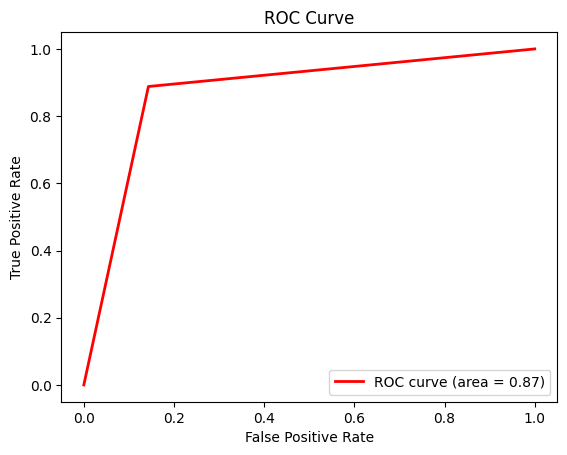

In [ ]:
# Calculate and plot the ROC curve
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='red', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
# plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()